In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

# Find the dataset relative to the notebook's working directory or its parent
dataset_name = "maharashtra_agriculture_dataset.xlsx"
search_roots = [Path.cwd(), Path.cwd().parent]
matches = [
    path
    for root in search_roots
    for path in root.rglob(dataset_name)
    if path.is_file()
]

if matches:
    DATA_PATH = matches[0]
else:
    expected_path = Path.cwd().parent / "data" / "raw" / dataset_name
    raise FileNotFoundError(
        f"Dataset not found. Searched from {Path.cwd()} and its parent.\n"
        f"Place '{dataset_name}' in {expected_path.parent} or update dataset_name."
    )

# Load Excel dataset
df = pd.read_excel(DATA_PATH, engine="openpyxl")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Dataset shape: (2500, 35)
Number of rows: 2500
Number of columns: 35


,Record_ID,District,City,Latitude,Longitude,Soil_Type,Soil_Color,Soil_pH,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Organic_Carbon_pct,Soil_Moisture_pct,Electrical_Conductivity_dS_m,Avg_Temperature_C,Rainfall_mm,Humidity_pct,Crop,Crop_Season,Crop_Duration_Days,Irrigation_Type,Farm_Area_Acres,Fertilizer_kg_acre,Pesticide_L_acre,Yield_kg_acre,Production_kg,Market_Price_Rs_kg,Total_Cost_Rs,Revenue_Rs,Profit_Rs,Drought_Risk_pct,Flood_Risk_pct,Overall_Risk_pct,Recommended_Crop,Recommendation_Score
0,1,Aurangabad,Chhatrapati Sambhajinagar,19.88,75.34,Black,Black,7.82,262.9,8.3,238.4,0.77,31.3,0.74,30.2,588.9,58.4,Gram,Rabi,110,Sprinkler,16.63,119.8,3.50,1434.3,23856.2,64.8,817651.4,1546569.3,728918.0,16.5,21.1,26.8,Gram,88.9
1,2,Sangli,Sangli,16.85,74.58,Black,Black,6.95,248.6,24.6,332.7,0.83,57.2,0.61,26.0,576.7,59.3,Grapes,Annual,210,Rainfed,3.47,125.6,3.50,18525.9,64257.4,101.6,964374.1,6530727.3,5566353.1,17.8,24.6,28.4,Tur,86.5
2,3,Gondia,Gondia,21.46,80.20,Alluvial,Dark Brown,6.68,233.8,25.5,295.9,0.96,32.2,0.64,25.4,1120.6,70.1,Sugarcane,Annual,330,Rainfed,13.70,124.8,7.22,91000.5,1246675.0,12.9,2393831.0,16051010.4,13657179.4,19.9,27.6,31.6,Rice,82.9
3,4,Gadchiroli,Gadchiroli,20.18,79.99,Red Loamy,Red,5.85,117.8,21.5,197.8,0.67,41.2,0.81,27.2,1535.8,73.2,Pomegranate,Annual,210,Rainfed,1.43,56.2,8.95,7801.2,11167.6,65.0,181452.6,726359.5,544907.0,0.0,46.5,35.6,Rice,77.3
4,5,Parbhani,Parbhani,19.27,76.78,Black,Black,6.81,183.7,15.0,332.0,0.59,33.3,1.20,30.8,829.5,50.5,Groundnut,Kharif,110,Rainfed,2.83,202.5,6.01,1771.7,5016.5,65.3,125770.1,327441.6,201671.5,0.0,32.1,25.3,Groundnut,81.1


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())

profile = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

display(profile)
display(df.describe(include="all").T)

Rows: 2500
Columns: 35
Duplicate rows: 0


,Data Type,Missing Values,Missing Percentage,Unique Values
Record_ID,int64,0,0.0,2500
District,str,0,0.0,35
City,str,0,0.0,35
Latitude,float64,0,0.0,35
Longitude,float64,0,0.0,34
Soil_Type,str,0,0.0,5
Soil_Color,str,0,0.0,5
Soil_pH,float64,0,0.0,289
Nitrogen_kg_ha,float64,0,0.0,1382
Phosphorus_kg_ha,float64,0,0.0,338


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Record_ID,2500.0,NaN,NaN,NaN,1250.5,721.83216,1.0,625.75,1250.5,1875.25,2500.0
District,2500,35,Palghar,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,2500,35,Palghar,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,2500.0,NaN,NaN,NaN,19.445452,1.421657,16.17,18.52,19.72,20.7,21.46
Longitude,2500.0,NaN,NaN,NaN,75.952336,2.17844,72.77,74.02,75.88,77.3,80.2
Soil_Type,2500,5,Black,1636,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_Color,2500,5,Black,1269,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_pH,2500.0,NaN,NaN,NaN,7.008216,0.678819,5.0,6.73,7.12,7.51,8.0
Nitrogen_kg_ha,2500.0,NaN,NaN,NaN,205.0718,52.800588,60.0,174.075,213.95,242.0,350.0
Phosphorus_kg_ha,2500.0,NaN,NaN,NaN,20.38096,7.427623,5.0,15.475,20.4,25.5,46.2


In [6]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    missing.plot(kind="bar", figsize=(12, 5))
    plt.title("Missing Values by Column")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

No missing values found.


In [7]:
crop_col = next(
    (c for c in df.columns if "crop" in c),
    None
)

if crop_col:
    crop_counts = df[crop_col].value_counts().head(15)

    crop_counts.plot(kind="bar", figsize=(12, 5))
    plt.title("Top 15 Crops in Maharashtra Dataset")
    plt.xlabel("Crop")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    display(crop_counts.to_frame("Record Count"))
else:
    print("Crop column not detected. Check df.columns.")

Crop column not detected. Check df.columns.


In [8]:
soil_col = next(
    (c for c in df.columns if "soil_type" in c or c == "soil"),
    None
)

if soil_col:
    plt.figure(figsize=(10, 5))
    sns.countplot(
        data=df,
        y=soil_col,
        order=df[soil_col].value_counts().index
    )
    plt.title("Distribution of Soil Types")
    plt.xlabel("Number of Records")
    plt.ylabel("Soil Type")
    plt.tight_layout()
    plt.show()
else:
    print("Soil type column not detected.")

Soil type column not detected.


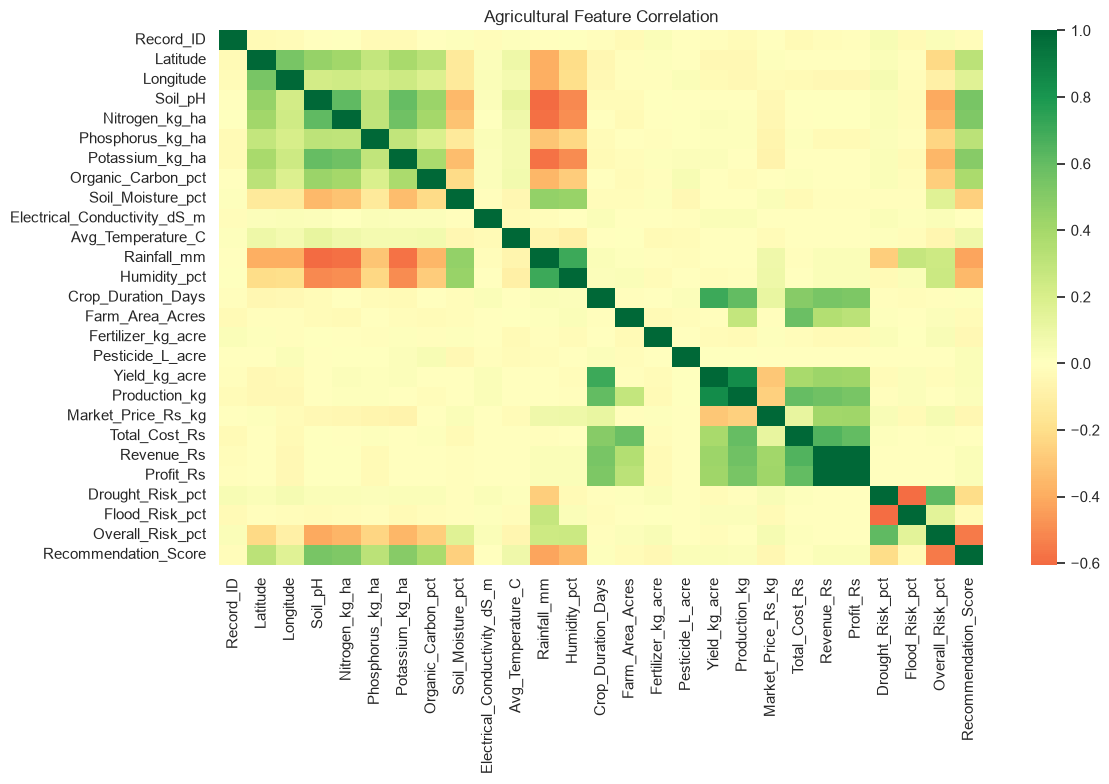

In [11]:
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    correlation = numeric_df.corr()

    plt.figure(figsize=(12, 8))
    sns.heatmap(
        correlation,
        annot=numeric_df.shape[1] <= 10,
        cmap="RdYlGn",
        center=0,
        fmt=".2f"
    )
    plt.title("Agricultural Feature Correlation")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numeric columns are required.")